# E-commerce Customer Segmentation (RFM Analysis)


## Objective
Analyze e-commerce transactions, calculate customer RFM scores,
identify customer segments, visualize purchasing patterns, and
recommend marketing strategies.

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project paths
DATA_PATH = Path("../data/Online Retail.xlsx")
OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the dataset
df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



## 1. Initial Data Exploration

### Objective
The objective of this step is to understand the structure,
size, columns, and data types of the Online Retail dataset
before performing data cleaning and preprocessing.

### Dataset Description
The Online Retail dataset contains transaction-level data
from an online retail business. It includes invoice numbers,
product information, quantities, invoice dates, unit prices,
customer IDs, and countries.

### Exploration Activities
- Check dataset dimensions.
- Inspect column names.
- Examine data types and non-null counts.
- Identify missing values and duplicate records.
- Review numerical summary statistics.
mmary statistics.
se quantities.


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)


Number of rows: 541909
Number of columns: 8
Dataset shape: (541909, 8)


## Display column names

In [4]:

print("Column names in the dataset:")

for column in df.columns:
    print(column)


Column names in the dataset:
InvoiceNo
StockCode
Description
Quantity
InvoiceDate
UnitPrice
CustomerID
Country


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB



### Data Quality Assessment

Data quality checks help identify issues that may affect
the accuracy of the analysis.

The following checks will be performed:
1. Count missing values in each column.
2. Identify duplicate records.
3. Examine descriptive statistics.
4. Determine which columns require cleaning.

The results will guide the data cleaning and preprocessing
stage before customer segmentation.


In [6]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values.to_frame(name="Missing Count"))

print("\nTotal missing cells:", df.isnull().sum().sum())


Missing values in each column:


,Missing Count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Total missing cells: 136534


In [7]:

duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)


Total duplicate rows: 5268


In [8]:

# Step 6.6: Generate descriptive statistics

display(df.describe())


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



### Initial Data Exploration — Findings

- The dataset contains 541,909 transaction records and 8 columns.
- A total of 136,534 missing cells were identified.
- A total of 5,268 duplicate rows were identified.
- Negative quantities and unit prices were observed.
- Customer identifiers and product descriptions require missing-value assessment.
- Data cleaning is required before customer-level RFM analysis.

### Conclusion

Initial exploration identified missing values, duplicate records,
and unusual transaction values. The next step will clean the
dataset using documented rules while preserving the original
data for comparison.



## 2. Data Cleaning and Preprocessing

### Objective
Prepare the Online Retail dataset for RFM customer segmentation
by identifying and handling duplicate records, missing values,
invalid transaction values, and cancellation invoices.

### Data Cleaning Activities
1. Create a working copy of the original dataset.
2. Remove duplicate rows.
3. Convert columns to appropriate data types.
4. Remove records missing required RFM fields.
5. Identify and exclude cancellation invoices.
6. Exclude non-positive quantities and unit prices for the
   positive-purchase analysis.
7. Calculate transaction sales value.
8. Validate the cleaned dataset.

### Data Quality Principle
The original dataset will remain unchanged. All cleaning
operations will be performed on a separate working copy.


In [9]:

# Step 7.1: Create a working copy

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)


Original dataset shape: (541909, 8)
Working dataset shape: (541909, 8)


In [10]:

# Step 7.2: Remove duplicate rows

before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

after_duplicates = len(df_clean)

print("Rows before duplicate removal:", before_duplicates)
print("Duplicate rows removed:", before_duplicates - after_duplicates)
print("Rows after duplicate removal:", after_duplicates)
print("Remaining duplicate rows:", df_clean.duplicated().sum())


Rows before duplicate removal: 541909
Duplicate rows removed: 5268
Rows after duplicate removal: 536641
Remaining duplicate rows: 0



### Handling Missing Values

Missing values were identified during initial data exploration.
For this customer segmentation project, records without an invoice
number, invoice date, quantity, unit price, or customer ID cannot
be used reliably for customer-level RFM calculations.

Rows missing these required fields will be removed. Missing product
descriptions and other optional fields will be assessed separately.

The number of removed records will be documented to maintain
transparency in the data cleaning process.


In [11]:

# Step 7.3: Handle missing values

required_columns = [
    "InvoiceNo",
    "InvoiceDate",
    "Quantity",
    "UnitPrice",
    "CustomerID"
]

before_missing = len(df_clean)

df_clean = df_clean.dropna(
    subset=required_columns
).copy()

print("Rows before handling required missing values:", before_missing)
print("Rows removed:", before_missing - len(df_clean))
print("Rows remaining:", len(df_clean))

print("\nMissing values in required columns:")
print(df_clean[required_columns].isnull().sum())


Rows before handling required missing values: 536641
Rows removed: 135037
Rows remaining: 401604

Missing values in required columns:
InvoiceNo      0
InvoiceDate    0
Quantity       0
UnitPrice      0
CustomerID     0
dtype: int64


In [12]:

# Step 7.4: Convert data types

df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)

# Remove records that failed conversion
df_clean = df_clean.dropna(
    subset=required_columns
).copy()

# Standardize invoice numbers
df_clean["InvoiceNo"] = (
    df_clean["InvoiceNo"].astype(str).str.strip()
)

# Identify cancellation invoices
cancellation_mask = df_clean["InvoiceNo"].str.startswith("C")

print("Cancellation invoice rows:", cancellation_mask.sum())
print("\nExample cancellation records:")

display(
    df_clean.loc[cancellation_mask].head()
)


Cancellation invoice rows: 8872

Example cancellation records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [13]:

# Step 7.5: Filter positive purchase transactions

before_filtering = len(df_clean)

# Exclude cancellation invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].str.startswith("C")
].copy()

# Exclude non-positive quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

print("Rows before purchase filtering:", before_filtering)
print("Rows after purchase filtering:", len(df_clean))
print("Rows excluded:", before_filtering - len(df_clean))


Rows before purchase filtering: 401604
Rows after purchase filtering: 392692
Rows excluded: 8912


In [14]:

# Step 7.6: Calculate transaction sales

df_clean["Sales"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Total sales:", round(df_clean["Sales"].sum(), 2))
print("Number of cleaned transactions:", len(df_clean))
print("Unique customers:", df_clean["CustomerID"].nunique())

display(df_clean.head())


Total sales: 8887208.89
Number of cleaned transactions: 392692
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [15]:

# Step 7.7: Final data quality validation

print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining duplicate rows:")
print(df_clean.duplicated().sum())

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nInvalid quantities:", (df_clean["Quantity"] <= 0).sum())
print("Invalid unit prices:", (df_clean["UnitPrice"] <= 0).sum())

print("\nDate range:")
print(df_clean["InvoiceDate"].min())
print(df_clean["InvoiceDate"].max())


Cleaned dataset shape: (392692, 9)

Remaining duplicate rows:
0

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Sales          0
dtype: int64

Invalid quantities: 0
Invalid unit prices: 0

Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00


In [16]:

# Step 7.8: Export cleaned data

cleaned_file = OUTPUT_DIR / "cleaned_online_retail.csv"

df_clean.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved to:")
print(cleaned_file.resolve())


Cleaned dataset saved to:
C:\Users\Chetan Patil\OneDrive\Documents\Data_Analytics_Internship\Project 3 E-Commerce Customer Segmentation (RFM Analysis)\outputs\cleaned_online_retail.csv



### Data Cleaning Summary

The original Online Retail dataset was copied into a separate
working DataFrame before preprocessing.

The cleaning process included:
- Removal of duplicate records.
- Handling of missing required RFM fields.
- Validation of dates and numerical values.
- Identification and exclusion of cancellation invoices.
- Exclusion of non-positive quantities and unit prices.
- Calculation of transaction sales values.
- Validation of the final cleaned dataset.

The cleaned dataset was exported for subsequent customer-level
RFM feature engineering and segmentation.

### Next Step
Calculate Recency, Frequency, and Monetary metrics for each
customer using the cleaned transaction data.



## 3. RFM Feature Engineering

### Objective
Calculate customer-level Recency, Frequency, and Monetary (RFM)
metrics using the cleaned Online Retail transaction dataset.

### RFM Definitions
- Recency: Number of days since the customer's most recent purchase.
- Frequency: Number of distinct invoices associated with the customer.
- Monetary: Total sales value generated by the customer.

### Methodology
1. Determine the RFM reference date.
2. Group transactions by CustomerID.
3. Calculate Recency, Frequency, and Monetary values.
4. Validate the customer-level RFM table.
5. Export the results for further analysis.

### Business Importance
RFM metrics help identify recently active customers, frequent buyers,
and customers contributing higher recorded sales value. These metrics
will be used to assign customer scores and develop business segments.


In [17]:

# Step 8.1: Define the RFM reference date

snapshot_date = (
    df_clean["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

print("Latest transaction date:",
      df_clean["InvoiceDate"].max())

print("RFM reference date:", snapshot_date)


Latest transaction date: 2011-12-09 12:50:00
RFM reference date: 2011-12-10 00:00:00


In [18]:

# Step 8.2: Prepare customer identifiers

df_rfm = df_clean.copy()

df_rfm["CustomerID"] = (
    pd.to_numeric(df_rfm["CustomerID"])
    .astype("Int64")
    .astype(str)
)

# Step 8.3: Calculate customer-level RFM metrics

rfm = df_rfm.groupby("CustomerID").agg(
    Recency=(
        "InvoiceDate",
        lambda dates: (
            snapshot_date - dates.max().normalize()
        ).days
    ),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum")
).reset_index()

# Round Monetary values to two decimal places
rfm["Monetary"] = rfm["Monetary"].round(2)

print("RFM calculation completed!")
print("Total customers:", rfm["CustomerID"].nunique())
print("RFM table shape:", rfm.shape)

display(rfm.head(10))


RFM calculation completed!
Total customers: 4338
RFM table shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,3,7,4310.00
2,12348,76,4,1797.24
3,12349,19,1,1757.55
4,12350,311,1,334.40
5,12352,37,8,2506.04
6,12353,205,1,89.00
7,12354,233,1,1079.40
8,12355,215,1,459.40
9,12356,23,3,2811.43


In [19]:

# Step 8.4: Validate RFM metrics

print("Missing values:")
print(rfm.isnull().sum())

print("\nDuplicate customer IDs:",
      rfm["CustomerID"].duplicated().sum())

print("\nRecency minimum:", rfm["Recency"].min())
print("Frequency minimum:", rfm["Frequency"].min())
print("Monetary minimum:", rfm["Monetary"].min())

print("\nDescriptive statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


Missing values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Duplicate customer IDs: 0

Recency minimum: 1
Frequency minimum: 1
Monetary minimum: 3.75

Descriptive statistics:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.00000
mean,93.059474,4.272015,2048.68808
std,100.012264,7.697998,8985.23022
min,1.000000,1.000000,3.75000
25%,18.000000,1.000000,306.48250
50%,51.000000,2.000000,668.57000
75%,142.750000,5.000000,1660.59750
max,374.000000,209.000000,280206.02000


In [20]:

# Step 8.5: Save customer-level RFM metrics

rfm_file = OUTPUT_DIR / "rfm_metrics.csv"

rfm.to_csv(rfm_file, index=False)

print("RFM metrics saved successfully!")
print(rfm_file.resolve())


RFM metrics saved successfully!
C:\Users\Chetan Patil\OneDrive\Documents\Data_Analytics_Internship\Project 3 E-Commerce Customer Segmentation (RFM Analysis)\outputs\rfm_metrics.csv



### RFM Feature Engineering — Findings

Customer-level RFM metrics were calculated from the cleaned
transaction dataset.

- Recency measures the number of days since the last purchase.
- Frequency measures the number of distinct invoices per customer.
- Monetary measures total recorded purchase value per customer.
- The reference date is one day after the latest valid transaction.
- The resulting RFM table is saved for subsequent scoring and
  customer segmentation.

### Conclusion
RFM feature engineering transforms transaction-level records into
customer-level metrics. These metrics provide the foundation for
customer scoring, segment classification, and marketing recommendations.



## 4. RFM Scoring

### Objective
Assign scores from 1 to 5 to each customer based on Recency,
Frequency, and Monetary value.

### Scoring Methodology
- Recency: Customers who purchased more recently receive higher scores.
- Frequency: Customers with more distinct orders receive higher scores.
- Monetary: Customers with higher total purchase value receive higher scores.

### Interpretation
Each customer receives three individual scores.
These scores are combined into a three-digit RFM score.

For example:
- 555 represents high scores across all three metrics.
- 111 represents low scores across all three metrics.

RFM scores help identify valuable customers and support
business-oriented customer segmentation.


In [21]:

# Step 9.1: Calculate RFM scores

# Recency: fewer days since last purchase = higher score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: more orders = higher score
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spend = higher score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

print("RFM scores calculated successfully!")

display(rfm.head(10))


RFM scores calculated successfully!


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346,326,1,77183.60,1,1,5
1,12347,3,7,4310.00,5,5,5
2,12348,76,4,1797.24,2,4,4
3,12349,19,1,1757.55,4,1,4
4,12350,311,1,334.40,1,1,2
5,12352,37,8,2506.04,3,5,5
6,12353,205,1,89.00,1,1,1
7,12354,233,1,1079.40,1,1,4
8,12355,215,1,459.40,1,1,2
9,12356,23,3,2811.43,4,3,5


In [22]:

# Step 9.2: Combine R, F, and M scores

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

display(
    rfm[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(10)
)


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,3,7,4310.00,5,5,5,555
2,12348,76,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,311,1,334.40,1,1,2,112
5,12352,37,8,2506.04,3,5,5,355
6,12353,205,1,89.00,1,1,1,111
7,12354,233,1,1079.40,1,1,4,114
8,12355,215,1,459.40,1,1,2,112
9,12356,23,3,2811.43,4,3,5,435


In [23]:

# Step 9.3: Inspect score distributions

print("Recency score distribution:")
print(rfm["R_Score"].value_counts().sort_index())

print("\nFrequency score distribution:")
print(rfm["F_Score"].value_counts().sort_index())

print("\nMonetary score distribution:")
print(rfm["M_Score"].value_counts().sort_index())

print("\nTop 10 RFM score combinations:")
display(rfm["RFM_Score"].value_counts().head(10))


Recency score distribution:
R_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

Frequency score distribution:
F_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

Monetary score distribution:
M_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

Top 10 RFM score combinations:


RFM_Score
555    347
111    184
455    173
121    154
112    127
444    109
122     90
344     86
544     85
233     84
Name: count, dtype: int64

In [24]:

# Step 9.4: Export RFM scores

score_file = OUTPUT_DIR / "rfm_scored_customers.csv"

rfm.to_csv(score_file, index=False)

print("Scored customer data saved to:")
print(score_file.resolve())


Scored customer data saved to:
C:\Users\Chetan Patil\OneDrive\Documents\Data_Analytics_Internship\Project 3 E-Commerce Customer Segmentation (RFM Analysis)\outputs\rfm_scored_customers.csv



### RFM Scoring — Conclusion

Customers were assigned scores from 1 to 5 for Recency,
Frequency, and Monetary value.

The three individual scores were combined into a single
RFM score for easier comparison of customer purchasing behaviour.

Higher scores indicate more desirable purchasing behaviour
under the selected scoring methodology.

The scored customer dataset will be used in the next stage
to assign interpretable customer segments.



## 5. Customer Segmentation

### Objective
Classify customers into meaningful business segments using
their Recency, Frequency, and Monetary scores.

### Customer Segments
- Champions: Recent, frequent, high-spending customers.
- Loyal Customers: Customers with consistently strong purchasing activity.
- Recent / New Customers: Recently active customers with low order frequency.
- At-Risk / Needs Attention: Previously frequent customers who have not purchased recently.
- Lost / Hibernating: Customers with low recency and frequency scores.
- Potential Loyalists: Customers who may develop into repeat buyers.

### Methodology
Business rules are applied to the RFM scores to assign an
interpretable segment label to each customer.

### Business Value
Customer segments help marketing teams prioritize loyalty,
retention, onboarding, and reactivation campaigns.


In [25]:

# Step 10.1: Assign business-friendly customer segments

def assign_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 3:
        return "Loyal Customers"

    elif r >= 4 and f <= 2:
        return "Recent / New Customers"

    elif r <= 2 and f >= 3:
        return "At-Risk / Needs Attention"

    elif r == 1 and f <= 2:
        return "Lost / Hibernating"

    else:
        return "Potential Loyalists"


rfm["Segment"] = rfm.apply(assign_segment, axis=1)

print("Customer segmentation completed!")

display(
    rfm[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score",
            "Segment"
        ]
    ].head(10)
)


Customer segmentation completed!


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,115,Lost / Hibernating
1,12347,3,7,4310.00,5,5,5,555,Champions
2,12348,76,4,1797.24,2,4,4,244,At-Risk / Needs Attention
3,12349,19,1,1757.55,4,1,4,414,Recent / New Customers
4,12350,311,1,334.40,1,1,2,112,Lost / Hibernating
5,12352,37,8,2506.04,3,5,5,355,Loyal Customers
6,12353,205,1,89.00,1,1,1,111,Lost / Hibernating
7,12354,233,1,1079.40,1,1,4,114,Lost / Hibernating
8,12355,215,1,459.40,1,1,2,112,Lost / Hibernating
9,12356,23,3,2811.43,4,3,5,435,Loyal Customers


In [26]:

# Step 10.2: Count customers by segment

segment_counts = (
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customer_Count")
)

display(segment_counts)

print("Total customers across all segments:",
      segment_counts["Customer_Count"].sum())


,Segment,Customer_Count
0,Loyal Customers,999
1,Champions,941
2,Potential Loyalists,758
3,Lost / Hibernating,667
4,At-Risk / Needs Attention,663
5,Recent / New Customers,310


Total customers across all segments: 4338


In [27]:

# Step 10.3: Calculate customer percentages

segment_counts["Percentage"] = (
    segment_counts["Customer_Count"]
    / segment_counts["Customer_Count"].sum()
    * 100
).round(2)

display(segment_counts)


,Segment,Customer_Count,Percentage
0,Loyal Customers,999,23.03
1,Champions,941,21.69
2,Potential Loyalists,758,17.47
3,Lost / Hibernating,667,15.38
4,At-Risk / Needs Attention,663,15.28
5,Recent / New Customers,310,7.15


In [28]:

# Step 10.4: Save segmented customer data

segmented_file = OUTPUT_DIR / "rfm_customer_segments.csv"

rfm.to_csv(segmented_file, index=False)

segment_summary_file = OUTPUT_DIR / "customer_segment_counts.csv"

segment_counts.to_csv(segment_summary_file, index=False)

print("Segmented customer file saved to:")
print(segmented_file.resolve())

print("\nSegment summary saved to:")
print(segment_summary_file.resolve())


Segmented customer file saved to:
C:\Users\Chetan Patil\OneDrive\Documents\Data_Analytics_Internship\Project 3 E-Commerce Customer Segmentation (RFM Analysis)\outputs\rfm_customer_segments.csv

Segment summary saved to:
C:\Users\Chetan Patil\OneDrive\Documents\Data_Analytics_Internship\Project 3 E-Commerce Customer Segmentation (RFM Analysis)\outputs\customer_segment_counts.csv



### Customer Segmentation — Findings

Customers have been classified into six business-friendly
segments using rule-based RFM scoring.

The segment count table summarizes the number and percentage
of customers in each group.

Champions represent customers with strong recency, frequency,
and monetary scores. At-Risk and Lost customers may require
retention or reactivation strategies, while Recent / New
Customers may benefit from onboarding campaigns.

The actual segment distribution will be used to prioritize
marketing recommendations.

### Conclusion
Rule-based RFM segmentation converts numerical customer
scores into interpretable groups that support business decisions.



## 6. Customer Segment Visualization

### Objective
Visualize customer distribution across RFM segments and compare
the revenue contribution of different customer groups.

### Visualizations
- Bar chart showing customer count by segment.
- Bar chart showing total revenue by segment.
- Scatter plot comparing customer frequency and monetary value.

### Business Value
Visualizations make it easier to identify important customer
groups and communicate findings to marketing stakeholders.


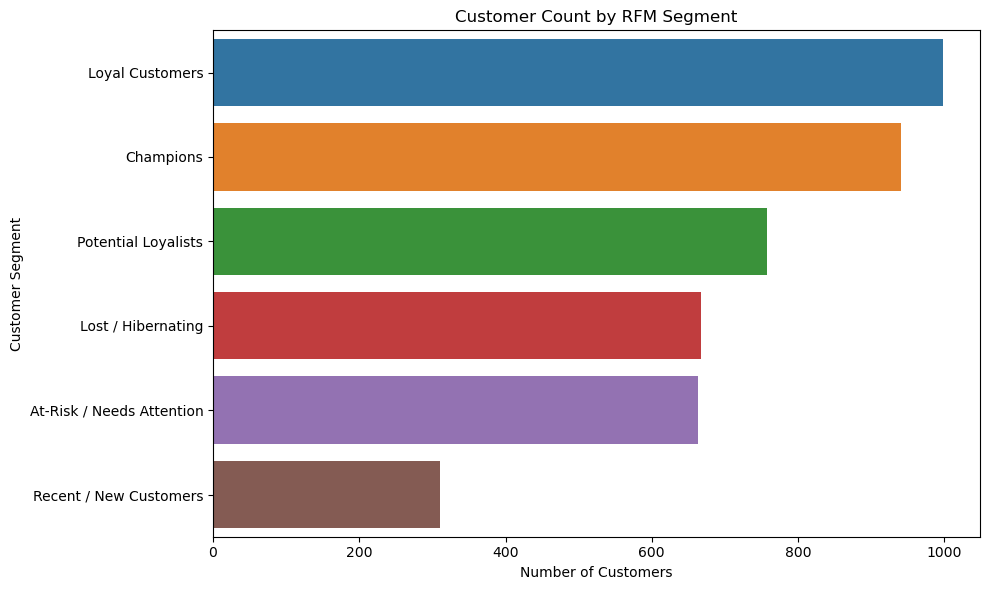

In [29]:

# Step 11.1: Plot customer count by segment

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_counts,
    x="Customer_Count",
    y="Segment"
)

plt.title("Customer Count by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()

plt.savefig(
    "../images/customer_segments.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [30]:

# Step 11.2: Calculate revenue by segment

revenue_summary = rfm.groupby("Segment", as_index=False).agg(
    Customers=("CustomerID", "nunique"),
    Total_Revenue=("Monetary", "sum"),
    Avg_Monetary=("Monetary", "mean")
)

revenue_summary = revenue_summary.sort_values(
    "Total_Revenue", ascending=False
)

display(revenue_summary.round(2))


,Segment,Customers,Total_Revenue,Avg_Monetary
1,Champions,941,5741913.58,6101.93
3,Loyal Customers,999,1493228.74,1494.72
0,At-Risk / Needs Attention,663,827416.57,1247.99
4,Potential Loyalists,758,372213.84,491.05
2,Lost / Hibernating,667,316679.04,474.78
5,Recent / New Customers,310,135757.12,437.93


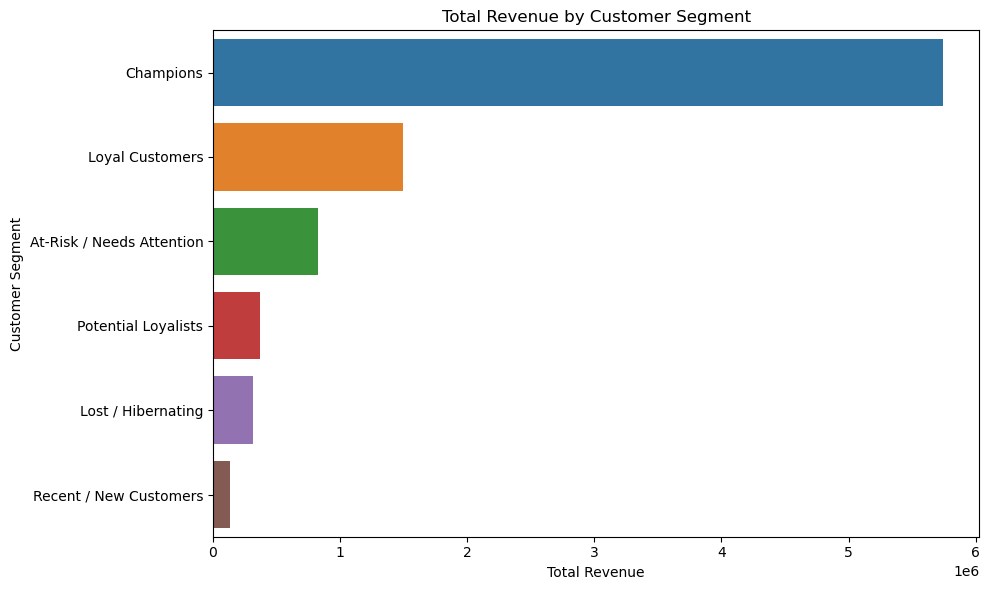

In [31]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=revenue_summary,
    x="Total_Revenue",
    y="Segment"
)

plt.title("Total Revenue by Customer Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")
plt.tight_layout()

plt.savefig(
    "../images/revenue_by_segment.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


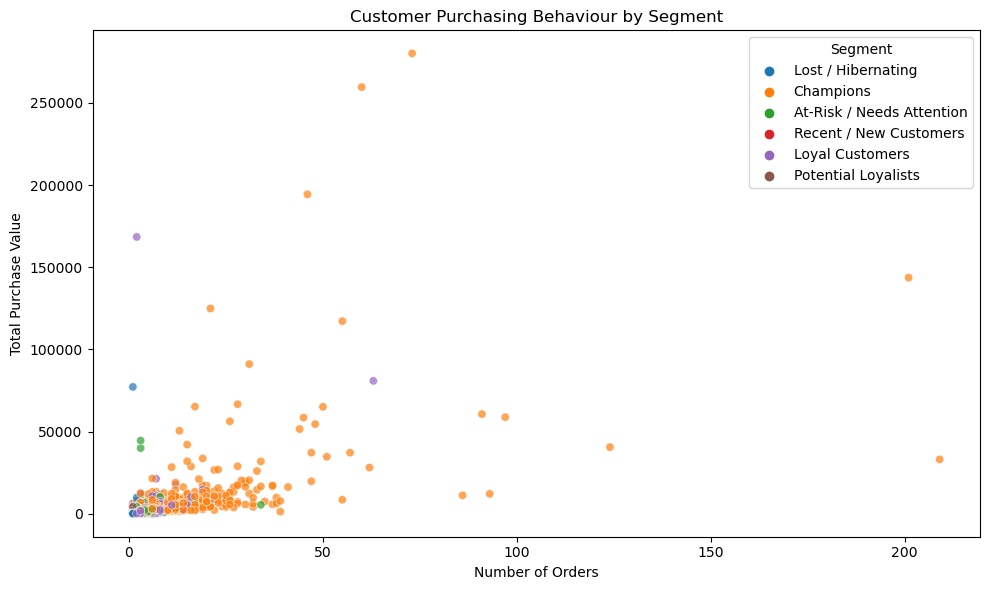

In [32]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Segment",
    alpha=0.7
)

plt.title("Customer Purchasing Behaviour by Segment")
plt.xlabel("Number of Orders")
plt.ylabel("Total Purchase Value")
plt.tight_layout()

plt.savefig(
    "../images/customer_frequency_monetary.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [33]:

revenue_summary.to_csv(
    OUTPUT_DIR / "segment_revenue_summary.csv",
    index=False
)

print("Revenue summary saved successfully!")


Revenue summary saved successfully!



### Visualization Findings

The customer count chart compares the size of each RFM segment.
The revenue chart compares the total recorded purchase value
generated by each segment.

The Frequency-versus-Monetary scatter plot shows differences
in customer purchasing patterns.

These visualizations support marketing prioritization by
combining customer counts with revenue contribution.

### Conclusion
Customer segment visualizations translate the RFM results
into business-friendly insights for decision-making.



## 7. Business Recommendations

### Objective
Translate RFM customer segments into actionable marketing
strategies that support customer retention, repeat purchases,
and revenue growth.

### Strategy
- Champions: Loyalty rewards and referral programmes.
- Loyal Customers: Personalized offers and cross-selling.
- Recent / New Customers: Welcome messages and second-purchase incentives.
- At-Risk / Needs Attention: Targeted win-back campaigns.
- Lost / Hibernating: Low-cost reactivation campaigns.
- Potential Loyalists: Relevant recommendations to encourage repeat purchases.

### Performance Measurement
Campaign effectiveness should be evaluated using repeat purchases,
incremental revenue, profit margin, customer retention, and return
on marketing investment.


In [34]:

# Step 12.1: Define marketing recommendations

campaigns = pd.DataFrame({
    "Segment": [
        "Champions",
        "Loyal Customers",
        "Recent / New Customers",
        "At-Risk / Needs Attention",
        "Lost / Hibernating",
        "Potential Loyalists"
    ],
    "Recommended_Campaign": [
        "Loyalty rewards, referrals, and early access",
        "Personalized offers and cross-selling",
        "Welcome campaign and second-purchase incentive",
        "Targeted win-back campaign",
        "Low-cost reactivation campaign",
        "Relevant product recommendations and repeat-purchase offers"
    ],
    "Success_Metric": [
        "Repeat purchase rate and customer retention",
        "Repeat purchase rate and revenue per customer",
        "Second-purchase conversion rate",
        "Reactivation rate and incremental revenue",
        "Reactivation cost and incremental profit",
        "Repeat purchase rate and segment migration"
    ]
})

display(campaigns)


,Segment,Recommended_Campaign,Success_Metric
0,Champions,"Loyalty rewards, referrals, and early access",Repeat purchase rate and customer retention
1,Loyal Customers,Personalized offers and cross-selling,Repeat purchase rate and revenue per customer
2,Recent / New Customers,Welcome campaign and second-purchase incentive,Second-purchase conversion rate
3,At-Risk / Needs Attention,Targeted win-back campaign,Reactivation rate and incremental revenue
4,Lost / Hibernating,Low-cost reactivation campaign,Reactivation cost and incremental profit
5,Potential Loyalists,Relevant product recommendations and repeat-pu...,Repeat purchase rate and segment migration


In [35]:

campaign_file = OUTPUT_DIR / "campaign_recommendations.csv"

campaigns.to_csv(campaign_file, index=False)

print("Campaign recommendations saved to:")
print(campaign_file.resolve())


Campaign recommendations saved to:
C:\Users\Chetan Patil\OneDrive\Documents\Data_Analytics_Internship\Project 3 E-Commerce Customer Segmentation (RFM Analysis)\outputs\campaign_recommendations.csv



### Business Interpretation

RFM segmentation enables the business to tailor marketing
campaigns to different customer purchasing patterns.

High-value customers may benefit from loyalty programmes,
while inactive customers may need targeted reactivation offers.
New customers can receive onboarding messages to encourage
their next purchase.

Recommendations should be prioritized using actual segment
size, revenue contribution, campaign cost, and profit margin.
A control group should be used where practical to measure
incremental campaign effectiveness.

### Conclusion
The analysis translates customer-level RFM metrics into
actionable marketing strategies. Campaign outcomes should be
validated using measurable business KPIs.



## 8. Final Outputs and Validation

### Objective
Export the final customer segmentation results, summary tables,
visualizations, and marketing recommendations.

### Deliverables
- Cleaned transaction dataset
- Customer-level RFM metrics
- RFM scores and customer segments
- Customer count and revenue summaries
- Customer segmentation visualizations
- Marketing campaign recommendations

All outputs should be checked for completeness before
preparing the final project report and GitHub repository.


In [36]:

# Save the final customer-level table

rfm.to_csv(
    OUTPUT_DIR / "rfm_customer_segments.csv",
    index=False
)

# Save summary tables
segment_counts.to_csv(
    OUTPUT_DIR / "customer_segment_counts.csv",
    index=False
)

revenue_summary.to_csv(
    OUTPUT_DIR / "segment_revenue_summary.csv",
    index=False
)

campaigns.to_csv(
    OUTPUT_DIR / "campaign_recommendations.csv",
    index=False
)

print("All final output tables exported successfully!")


All final output tables exported successfully!


In [37]:

# Check expected output files

expected_files = [
    "cleaned_online_retail.csv",
    "rfm_metrics.csv",
    "rfm_scored_customers.csv",
    "rfm_customer_segments.csv",
    "customer_segment_counts.csv",
    "segment_revenue_summary.csv",
    "campaign_recommendations.csv"
]

for filename in expected_files:
    path = OUTPUT_DIR / filename
    print(
        f"{filename}:",
        "Available" if path.exists() else "Missing"
    )


cleaned_online_retail.csv: Available
rfm_metrics.csv: Available
rfm_scored_customers.csv: Available
rfm_customer_segments.csv: Available
customer_segment_counts.csv: Available
segment_revenue_summary.csv: Available
campaign_recommendations.csv: Available
